# WEEK 10 Lecture: Binary trees and binary search trees

In week 9, we learned basic concepts of trees in general. This week, we will go in further details regarding the tree data structure.

We will learn, why certain search algorithms are so efficient with tree structure. We will also get an idea how these algorithms should be implemented.

## A short summary on tree data structure (general)

In week 9 we learned that a tree
* is a **hierarchical data** structure
* consists of nodes and edges like graphs
* there are specific names for certain types of nodes: **parents** are hierarchically above, **children** below, **siblings** are same level nodes that share the same parent
* a parent that *has no parent* is **the root** of the tree
* a child having no children is **a leaf**

In a tree, you will need a function
* that adds a new node
* traverses the tree, i.e. visits all nodes in the tree
* searches for a specific node
    - Breadth-first search (BFS): searches the nodes at the same level at once
    - Depth-first search (DFS): searches the nodes at the same path until it reaches a leaf and starts backtracking
* deletes a node

Further concepts:
* **height** (node) = the lenght of the longest path from the node to a leaf
* **height** (tree) = the length of the longest path from root to a leaf
* **depth** (node) = the length of the path from root to the node
* **depth** (tree) = the length of the path from root to the furthest leaf
* **level** = all nodes at the same depth
* **breadth** = number of nodes on certain level

All these terms and propertees are shown in the below picture by GeeksforGeeks:
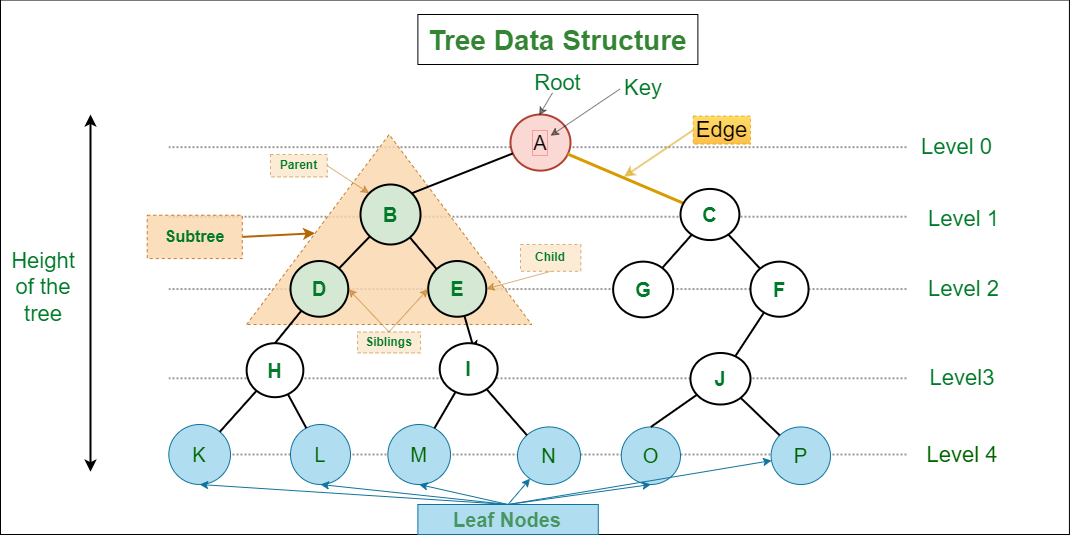

Here is another image demonstrating the terms **height**, **depth** and **level**
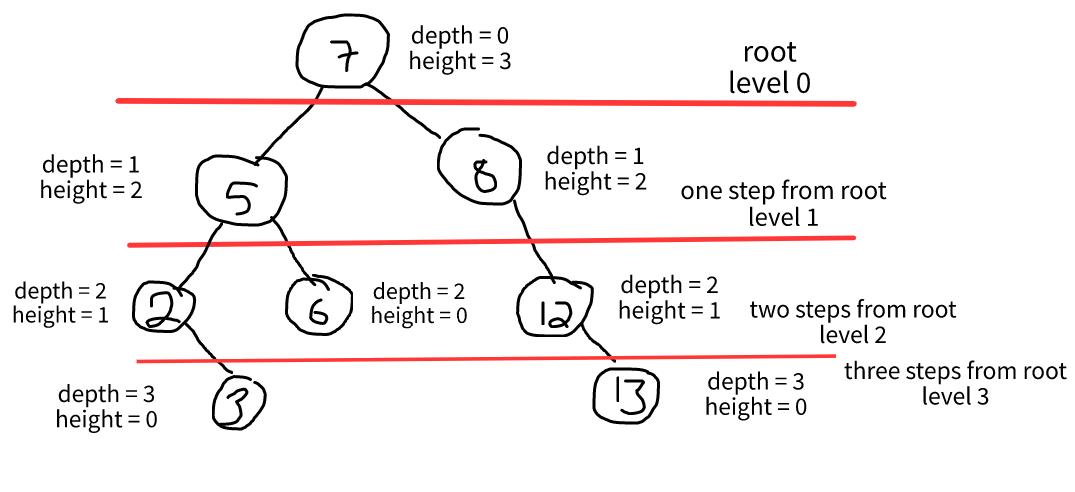

## Binary tree

**A binary tree** is a tree in which every node has 0, 1 or 2 children (i.e. at most 2 children).

**Further tree terminology**

1. A **rooted** binary tree has a root node and every node has at most two children.
2. A **full** binary tree (aka proper, plane or strict) is a tree in which *every node has either 0 or 2 children*. 
3. A **perfect** binary tree is a binary tree in which *all interior nodes have two children* and *all leaves have the same depth* or same level.
4. A **complete** binary tree is a binary tree in which every level, except possibly the last, is completely filled, and all nodes in the last level are as far left as possible. 
5. A **balanced** binary tree is a binary tree structure in which the left and right subtrees of every node differ in height by no more than 1.
6. A **degenerate** (or pathological) tree is where each parent node has only one associated child node.

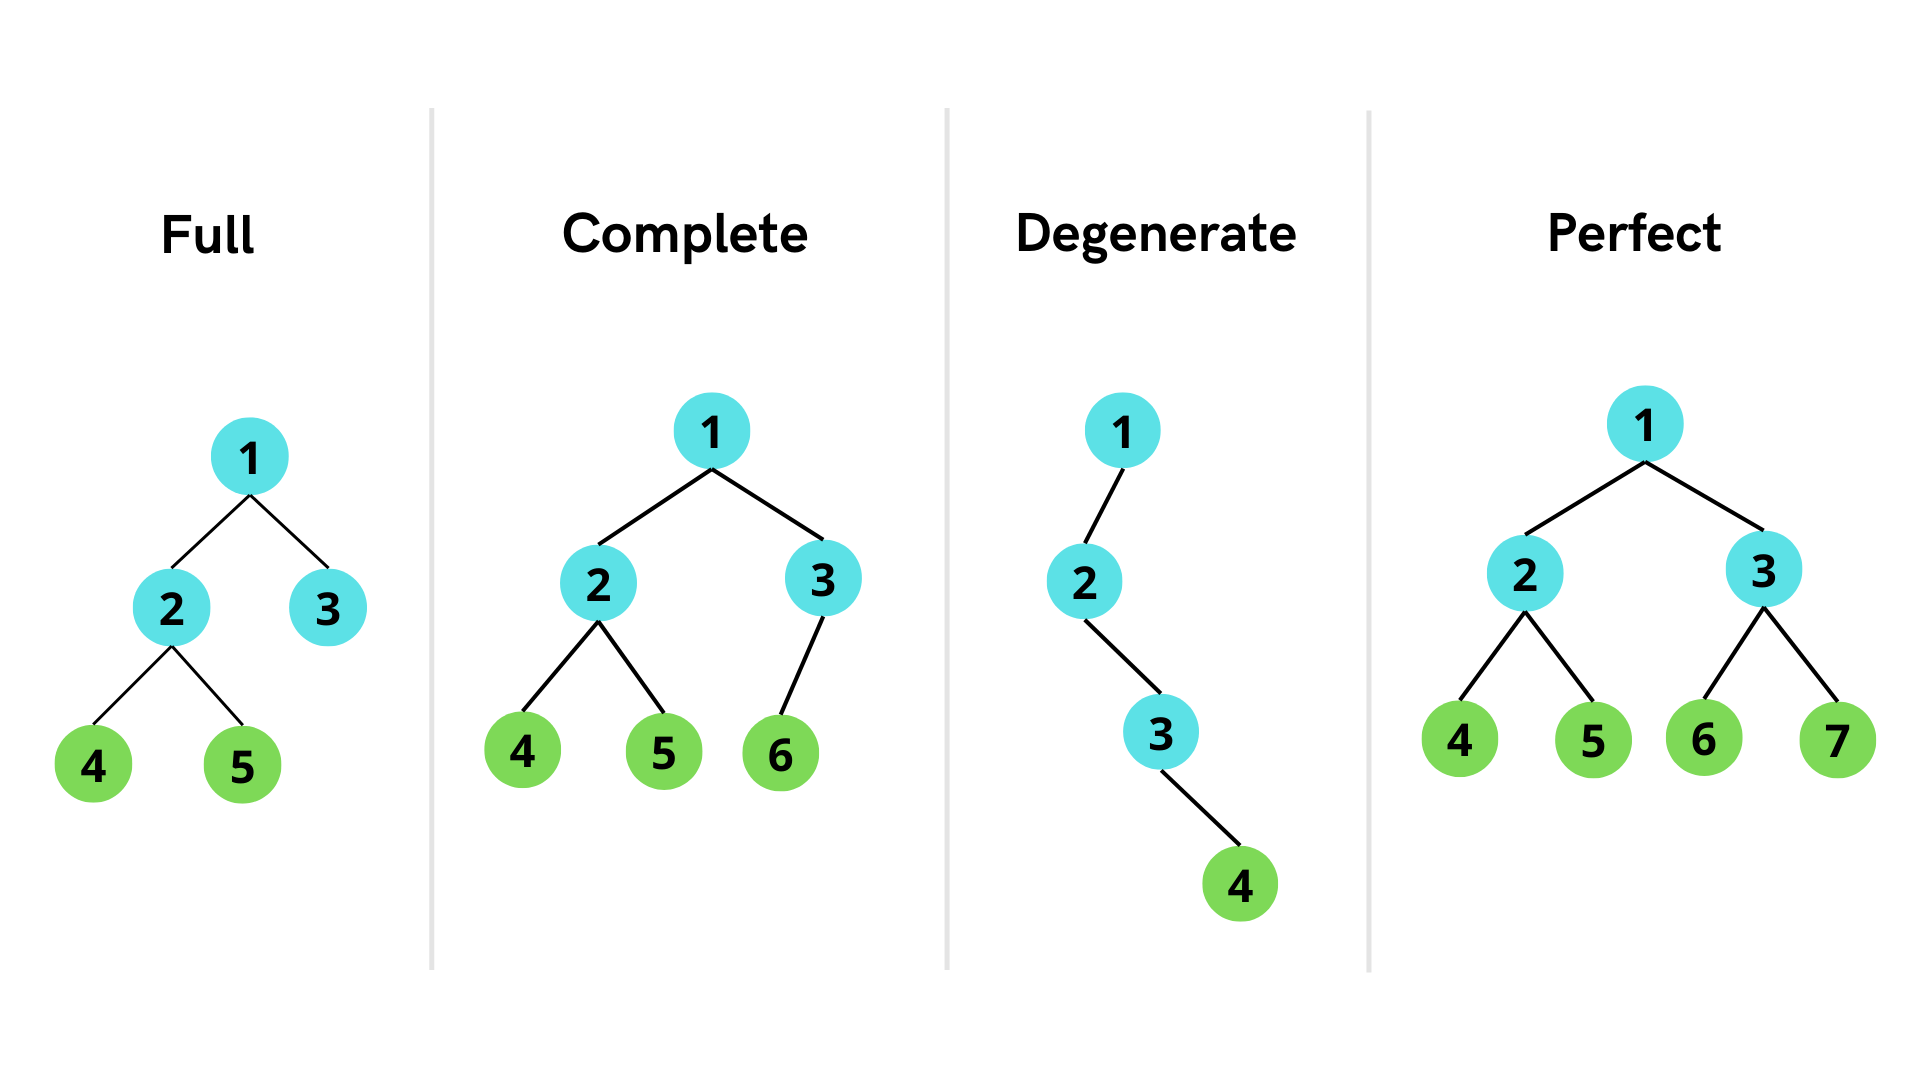

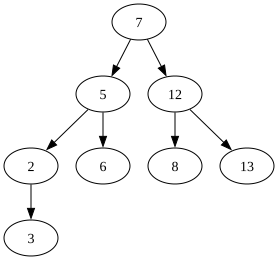

Print in pre-order:
7
5
2
3
6
12
8
13
Print in in-order:
2
3
5
6
7
8
12
13
Print in post-order:
3
2
6
5
8
13
12
7
Print in level-order:
[7]
[5, 12]
[2, 6, 8, 13]
[3]
YES, a node with value 12 found in BST!
NO node with value 4 found in BST!


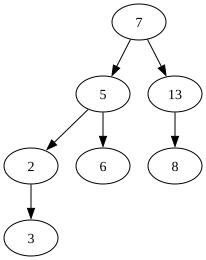

In [1]:
from graphviz import Digraph
from IPython.display import SVG
from collections import deque


'''
graphviz and ipython.display are used to visualize the generated tree.

This code defines a Node data structure with attributes value, left and right. Value is the integer value stored in node. 
Attribute left is a pointer to the left child of a node, once initialized it's None.
Attribute right is a pointer to the right child, correspondingly.

The Binary Search Tree (BST) data structure is a tree consisting of nodes. The left sub-tree consists of all values less than 
the value of the node, the right sub-tree of all values greater than the current node value.

The BST data structure has functions:
* add a node
* delete a node
* search a node
* preorder traversal (DF traversal)
* inorder traversal (DF traversal)
* postorder traversal (DF traversal)
* print for all traverlsal types
* visualise for graphical print
'''

class Node:
    def __init__(self,value):
        self.value = value
        self.left = None
        self.right = None
        
class BST:
    def __init__(self):
        self.root = None
        
    def _add(self, current, value):
        
        if self.root == None:
            self.root = Node(value)
        else:
            if value < current.value:
                if current.left == None:
                    current.left = Node(value)
                else:
                    self._add(current.left, value)
            else:
                if current.right == None:
                    current.right = Node(value)
                else:
                    self._add(current.right, value)
      
    def add(self, value):
        new_node = Node(value)
        
        if self.root == None:
            self.root = new_node
            
        else:
             self._add(self.root, value)
    
    def delete(self,root, key):
        """
        Delete a node with the given key from a binary search tree.

        :param root: The root of the binary search tree.
        :param key: The value of the node to be deleted.
        :return: The new root of the binary search tree.
        """
        if not root:
            return None

        if key < root.value:
            root.left = self.delete(root.left, key)
        elif key > root.value:
            root.right = self.delete(root.right, key)
        else:
            if not root.left:
                return root.right
            elif not root.right:
                return root.left
            else:
                temp = self.find_min(root.right)
                root.value = temp.value
                root.right = self.delete(root.right, temp.value)

        return root

    def find_min(self,root):
        while root.left:
            root = root.left
        return root
        
    # returns a node whose value == input value
    # if no node with input value is found, None is returned
    def _search(self, node, value):
        if node is None or node.value == value:
            return node          
        
        if value < node.value:
            return self._search(node.left, value)
        else:
            return self._search(node.right,value) 
        
    # prints the result of search: does a node with input value exist in the BST or not                   
    def search(self, value):
        result = self._search(self.root,value)
        
        if result is None:
            print(f"NO node with value {value} found in BST!")
        elif result.value == value:
            print(f"YES, a node with value {value} found in BST!")
    
    
    # visiting = print the value of the node
    def visit(self, node):
        print(node.value)
    
    # There are different types of in-depth traversals: pre-order, in-order and post-order
    # Here's an algorithm for all those
    
    # pre-order traversal
    def preorder(self, current):
        if current is not None:
            self.visit(current)
            self.preorder(current.left)
            self.preorder(current.right)
        
    def preprint(self):
        self.preorder(self.root)

    # inorder traversal
    def inorder(self, current):
        if current is not None:
            self.inorder(current.left)
            self.visit(current)
            self.inorder(current.right)
    
    def inprint(self):
        self.inorder(self.root)

    #postorder traversal
    def postorder(self, current):
        if current is not None:
            self.postorder(current.left)
            self.postorder(current.right)
            self.visit(current)
            
    def postprint(self):
        self.postorder(self.root)
    
    def level_order_traversal(self,root):
        """
        Perform level-order traversal on a binary tree.

        :param root: The root of the binary tree.
        :return: A list containing the values in the binary tree in level-order traversal order.
        """
        if not root:
            return []

        res = []
        q = deque([root])

        while q:
            level_size = len(q)
            level_vals = []
            for _ in range(level_size):
                node = q.popleft()
                level_vals.append(node.value)
                if node.left:
                    q.append(node.left)
                if node.right:
                    q.append(node.right)
            res.append(level_vals)

        return res

    def levelprint(self):
        levellist = self.level_order_traversal(self.root)
        for item in levellist:
            print(item)
                
    # visualize the BST with graphviz digraph
    def visualize(self):
        dot = Digraph(comment='Binary Tree')
        
        def add_nodes_edges(node):
            if node is None:
                return
            dot.node(str(node.value), str(node.value))
            if node.left is not None:
                dot.edge(str(node.value), str(node.left.value))
                add_nodes_edges(node.left)
            if node.right is not None:
                dot.edge(str(node.value), str(node.right.value))
                add_nodes_edges(node.right)
        
        add_nodes_edges(self.root)
        return SVG(dot.pipe(format='svg'))


# Driver code

BSTree = BST()

values = [7, 5, 2, 12, 8, 3, 6, 13]

for value in values:
    BSTree.add(value)

graph = BSTree.visualize()
#display the generated svg with ipython.display
display(graph)

import os
os.system('xdg-open binary_tree.png')

print("Print in pre-order:")
BSTree.preprint()

print("Print in in-order:")
BSTree.inprint()

print("Print in post-order:")
BSTree.postprint()

print("Print in level-order:")
BSTree.levelprint()

BSTree.search(12)
BSTree.search(4)

BSTree.delete(BSTree.root, 12)

graph2 = BSTree.visualize()
#display the generated svg with ipython.display
display(graph2)